# code_170 · Learn demand dynamics and replan battery operation

**Book:** section 32.4. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_170).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5370;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5370


<a id="learned-demand-and-shooting-plans"></a>
 ## Separate a learned disturbance model from known storage equations
 Thirty 24-hour source days supply an autoregressive residual model around a declared daily mean profile. Actions affect storage and grid purchases, not demand. Fit an intercept and residual coefficient by least squares; ten development days are diagnostics only. The battery has unit capacity, charge/discharge efficiency 0.92 and action rate 0.25. Every controller applies the same feasible-action projection. Cost combines time-of-use energy, peak-grid penalty 2×max(grid−1.1,0)², wear 0.02×|action| and an end-of-day storage penalty 0.5×(s−0.5)². MPC enumerates all 81 length-four action sequences (−0.25,0,0.25), implements only the first projected action, observes the next demand and replans. Its short-horizon terminal storage penalty is a declared heuristic. Compare no storage, a fixed price/reactive rule, persistence MPC and learned-demand MPC on ten familiar and ten changed final days. Shifted days have a larger evening peak and different residual persistence; neither model is refitted.


,regime,controller,mean_daily_cost,day_SD
0,Familiar,No storage,4.266641,0.306516
1,Familiar,Reactive,4.287027,0.443053
2,Familiar,Persistence,4.138903,0.336414
3,Familiar,Learned,4.126396,0.341481
4,Changed peak,No storage,5.800496,0.239999
5,Changed peak,Reactive,5.382552,0.241348
6,Changed peak,Persistence,5.290188,0.200361
7,Changed peak,Learned,5.284075,0.198741


,regime,model,steps_ahead,MAE
0,Familiar,Persistence,1,0.078165
1,Familiar,Learned,1,0.060205
2,Familiar,Persistence,2,0.124625
3,Familiar,Learned,2,0.075357
4,Familiar,Persistence,3,0.165852
5,Familiar,Learned,3,0.084425
6,Changed peak,Persistence,1,0.122794
7,Changed peak,Learned,1,0.115604
8,Changed peak,Persistence,2,0.182598
9,Changed peak,Learned,2,0.153293


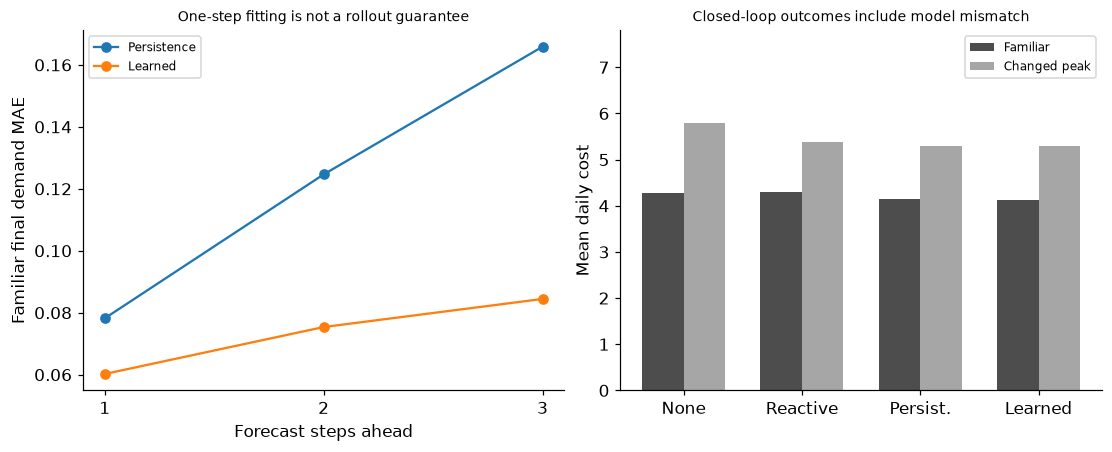

In [2]:
def mean_demand(t):return .65+.35*np.sin(2*np.pi*(np.asarray(t)-7)/24)**2
def price(t):return np.where((np.asarray(t)>=16)&(np.asarray(t)<21),.45,.15)
def day(seed,shift=False):
    gr=np.random.default_rng(seed);r=0.;out=[]
    for t in range(24):
        r=(.2 if shift else .75)*r+gr.normal(0,.08);out.append(max(.1,float(mean_demand(t)+r+(.55 if shift and 16<=t<21 else 0))))
    return np.array(out)
source=np.array([day(SEED+i) for i in range(30)]);dev=np.array([day(SEED+100+i) for i in range(10)]);res=source-mean_demand(np.arange(24));design=np.column_stack([np.ones(30*23),res[:,:-1].ravel()]);coef=np.linalg.lstsq(design,res[:,1:].ravel(),rcond=None)[0]
sequences=np.array(list(itertools.product([-.25,0,.25],repeat=4)))
def forecast(current,t,h,model):
    result=[];r=current-float(mean_demand(t))
    for k in range(h):
        if k==0:prediction=current
        elif model=='Persistence':prediction=current
        else:r=coef[0]+coef[1]*r;prediction=max(.1,float(mean_demand(t+k)+r))
        result.append(prediction)
    return np.array(result)
def project(s,a):return np.clip(a,-np.asarray(s)*.92,(1-np.asarray(s))/.92)
def advance(s,a):return s+np.where(a>=0,.92*a,a/.92)
def step_cost(d,a,t):
    grid=np.maximum(0,d+a);return price(t)*grid+2*np.maximum(grid-1.1,0)**2+.02*np.abs(a)
def plan(s,current,t,model):
    h=min(4,24-t);aa=sequences[:,:h];storage=np.full(len(aa),s);cost=np.zeros(len(aa));pred=forecast(current,t,h,model)
    for k in range(h):a=project(storage,aa[:,k]);cost+=step_cost(pred[k],a,t+k);storage=advance(storage,a)
    cost+=.5*(storage-.5)**2;j=int(cost.argmin());return float(project(s,aa[j,0])),aa[j].copy(),pred
def control(demand,mode):
    s=.5;trace=[];total=0.
    for t,d in enumerate(demand):
        if mode=='No storage':a=0.
        elif mode=='Reactive':a=.25 if t<7 and s<.75 else (-.25 if (16<=t<21 or d>1.1) else 0.)
        else:a,_,_=plan(s,d,t,mode)
        a=float(project(s,a));cost=float(step_cost(d,a,t));trace.append((t,s,d,a,cost));s=float(advance(s,a));assert -.000001<=s<=1.000001;total+=cost
    return total+.5*(s-.5)**2,trace
rows=[];traces={};forecast_rows=[]
for regime,shift in [('Familiar',False),('Changed peak',True)]:
    final=np.array([day(SEED+1000+i,shift) for i in range(10)])
    for mode in ['No storage','Reactive','Persistence','Learned']:
        costs=[]
        for i,d in enumerate(final):cost,trace=control(d,mode);costs.append(cost);traces[(regime,mode,i)]=trace
        rows.append({'regime':regime,'controller':mode,'mean_daily_cost':float(np.mean(costs)),'day_SD':float(np.std(costs,ddof=1))})
    for h in [1,2,3]:
        for model_name in ['Persistence','Learned']:
            errors=[abs(forecast(d[t],t,h+1,model_name)[h]-d[t+h]) for d in final for t in range(24-h)];forecast_rows.append({'regime':regime,'model':model_name,'steps_ahead':h,'MAE':float(np.mean(errors))})
dev_error=float(np.mean([abs(forecast(d[t],t,2,'Learned')[1]-d[t+1]) for d in dev for t in range(23)]));assert len(rows)==8 and len(source)==30 and len(sequences)==81
RESULTS.update(source_days=30,source_transition_pairs=690,development_days=10,development_used_for_selection=False,development_one_step_MAE=dev_error,demand_intercept=float(coef[0]),demand_residual_coefficient=float(coef[1]),planning_horizon=4,candidate_action_sequences=81,known_charge_discharge_efficiency=.92,final_days_per_regime=10,closed_loop_cost=rows,forecast_errors=forecast_rows,final_refits=0)
display(pd.DataFrame(rows));display(pd.DataFrame(forecast_rows));fig,axes=plt.subplots(1,2,figsize=(10,4))
for name in ['Persistence','Learned']:
    rr=[r for r in forecast_rows if r['model']==name and r['regime']=='Familiar'];axes[0].plot([r['steps_ahead'] for r in rr],[r['MAE'] for r in rr],marker='o',label=name)
axes[0].set(xticks=[1,2,3],xlabel='Forecast steps ahead',ylabel='Familiar final demand MAE',title='One-step fitting is not a rollout guarantee');axes[0].legend(fontsize=8)
for i,regime in enumerate(['Familiar','Changed peak']):axes[1].bar(np.arange(4)+(i-.5)*.35,[r['mean_daily_cost'] for r in rows if r['regime']==regime],width=.35,color=['.3','.65'][i],label=regime)
axes[1].set(xticks=range(4),xticklabels=['None','Reactive','Persist.','Learned'],ylabel='Mean daily cost',title='Closed-loop outcomes include model mismatch',ylim=(0,7.8));axes[1].legend(fontsize=8);plt.show()


<a id="receding-horizon-and-model-assumptions"></a>
 ## Inspect a planned sequence before executing its first action
 The plotted horizon is a real final-day decision, selected by a fixed hour 16 rather than by performance. Dashed demand is a model rollout, not an observation. Planned storage uses the known efficiency equations and action projection. The implemented action is the first element; future planned actions are replaced after new observations. Search can exploit a bad learned model or terminal heuristic even when every candidate is feasible inside that model. The final changed regime remains a held-out stress comparison and does not choose the planning horizon or fit parameters.


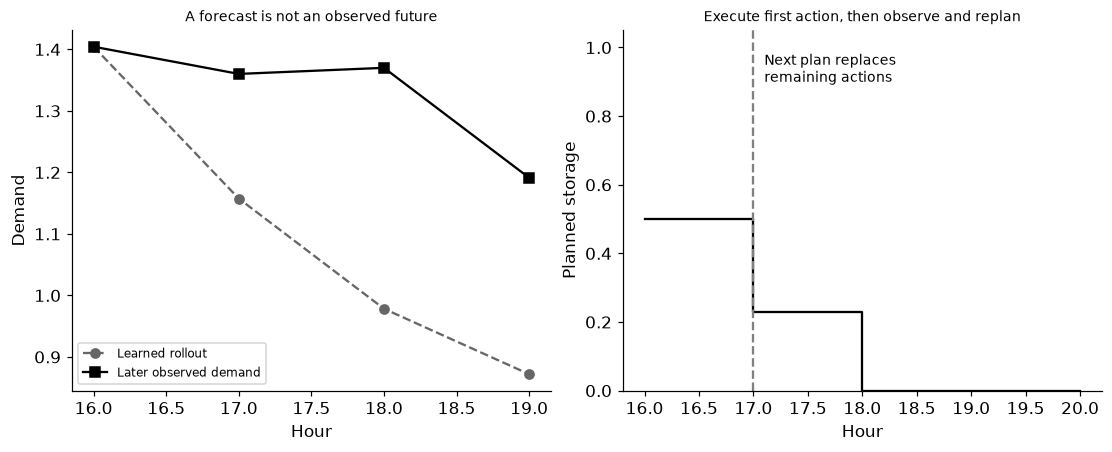

In [3]:
trace=traces[('Changed peak','Learned',0)];t=16;s=trace[t][1];d=trace[t][2];first,proposed,pred=plan(s,d,t,'Learned');planned_s=[s];actual_a=[]
for a in proposed:ap=float(project(planned_s[-1],a));actual_a.append(ap);planned_s.append(float(advance(planned_s[-1],ap)))
assert np.isclose(first,actual_a[0]) and len(planned_s)==5 and all(0-1e-12<=v<=1+1e-12 for v in planned_s)
RESULTS.update(example_plan_hour=16,example_planned_actions=actual_a,example_planned_storage=planned_s,example_predicted_demand=pred.tolist(),implemented_actions_per_plan=1)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(np.arange(t,t+4),pred,'o--',color='.4',label='Learned rollout');axes[0].plot(np.arange(t,t+4),[row[2] for row in trace[t:t+4]],'s-',color='black',label='Later observed demand');axes[0].set(xlabel='Hour',ylabel='Demand',title='A forecast is not an observed future');axes[0].legend(fontsize=8);axes[1].step(np.arange(t,t+5),planned_s,where='post',color='black',label='Planned storage');axes[1].axvline(t+1,color='.5',linestyle='--');axes[1].set(ylim=(0,1.05),xlabel='Hour',ylabel='Planned storage',title='Execute first action, then observe and replan');axes[1].text(t+1.1,.9,'Next plan replaces\nremaining actions',fontsize=9);plt.show()


In [4]:
summary={'example_id':'code_170','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['source-only fitted autoregressive demand residual model', 'known battery dynamics with efficiency and feasible-action projection', 'actual exhaustive finite action-sequence MPC and reactive control', 'independent multi-step forecast and closed-loop cost assessment', 'changed-demand regime and terminal-value assumptions retained'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["source-only fitted autoregressive demand residual model", "known battery dynamics with efficiency and feasible-action projection", "actual exhaustive finite action-sequence MPC and reactive control", "independent multi-step forecast and closed-loop cost assessment", "changed-demand regime and terminal-value assumptions retained"], "elapsed_seconds": 0.577, "example_id": "code_170", "hardware": "Darwin arm64 CPU", "results": {"candidate_action_sequences": 81, "closed_loop_cost": [{"controller": "No storage", "day_SD": 0.3065159083432039, "mean_daily_cost": 4.266641121100917, "regime": "Familiar"}, {"controller": "Reactive", "day_SD": 0.4430530564281684, "mean_daily_cost": 4.287026580147959, "regime": "Familiar"}, {"controller": "Persistence", "day_SD": 0.33641445516278834, "mean_daily_cost": 4.1389031619297665, "regime": "Familiar"}, {"controller": "Learned", "day_SD": 0.34148059330990493, "mean_daily_cost": 4.126396335683179, "regime":